<a href="https://colab.research.google.com/github/ANJARRIZANDI/simuteh-2330511035/blob/main/notebook/P6_morfologi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
import os

REPO_URL = "https://github.com/ANJARRIZANDI/simuteh-2330511035.git"
REPO_PATH = "/content/simuteh-2330511035"

if os.path.exists(REPO_PATH):
    print("Repository sudah tersedia:", REPO_PATH)
else:
    !git clone {REPO_URL} {REPO_PATH}

print("\nProses selesai.")

Repository sudah tersedia: /content/simuteh-2330511035

Proses selesai.


In [2]:
import os

os.chdir("/content/simuteh-2330511035")

print("Direktori aktif:", os.getcwd())
print("\nIsi repository:")
!ls

Direktori aktif: /content/simuteh-2330511035

Isi repository:
data  hasil  laporan  notebook	README.md  requirements.txt  src


In [3]:
import os
import nbformat as nbf

os.chdir("/content/simuteh-2330511035")

notebook_path = "notebook/P6_morfologi.ipynb"

if os.path.exists(notebook_path):
    print("Notebook P6 sudah tersedia.")
else:
    nb = nbf.v4.new_notebook()

    nb["cells"] = [
        nbf.v4.new_markdown_cell(
            "# PERTEMUAN 6: OPERASI MORFOLOGI DAN KOMPONEN TERHUBUNG\n\n"
            "**Praktikum Computer Vision – SIMUTEH**\n\n"
            "Notebook ini digunakan untuk mengerjakan operasi morfologi "
            "dan analisis komponen terhubung pada citra daun teh."
        )
    ]

    nbf.write(nb, notebook_path)
    print("Notebook P6 berhasil dibuat!")

print("Lokasi:", os.path.abspath(notebook_path))

Notebook P6 berhasil dibuat!
Lokasi: /content/simuteh-2330511035/notebook/P6_morfologi.ipynb


In [4]:
!ls -lh notebook/P6_morfologi.ipynb

-rw-r--r-- 1 root root 424 Nov 16 19:10 notebook/P6_morfologi.ipynb


In [17]:
import sys, os, json
sys.path.append("./src") # Karena Anda di Colab, pakai ./src
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

# Pastikan path PARAM sudah diubah ke ./hasil
PARAM = json.load(open("./hasil/param_praproses.json"))
label = pd.read_csv("./data/sintetis/label.csv")

# INI FUNGSI YANG DICARI OLEH ERROR ANDA
def muat(nama):
    img = baca(f"./data/sintetis/citra/{nama}")
    md  = cv2.imread(f"./data/sintetis/mask_daun/{nama}", 0)
    mb  = cv2.imread(f"./data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

         citra  IoU daun awal  komponen bercak awal  komponen acuan  \
0  teh_041.png          0.996                   178               6   
1  teh_021.png          0.998                   183               2   
2  teh_011.png          0.999                   197               0   

  IoU bercak awal  
0           0.498  
1           0.101  
2               -  


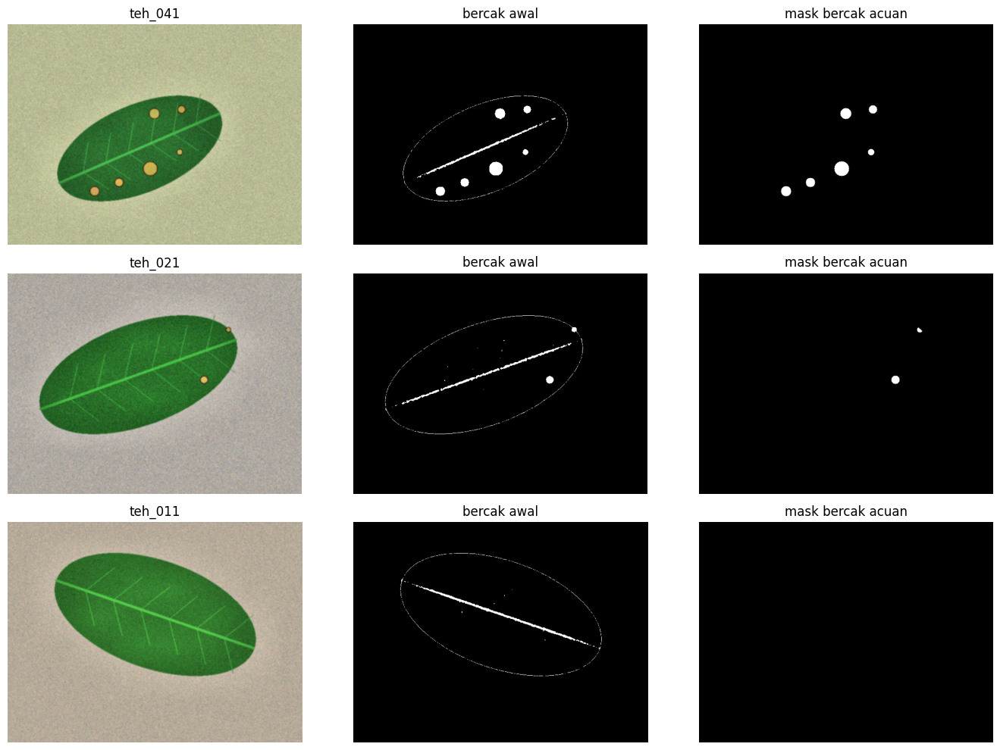

In [18]:
# Bagian 3. Operasi Morfologi pada Citra Biner
# Kode 3.1 Mask daun awal dan bercak awal
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])

    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

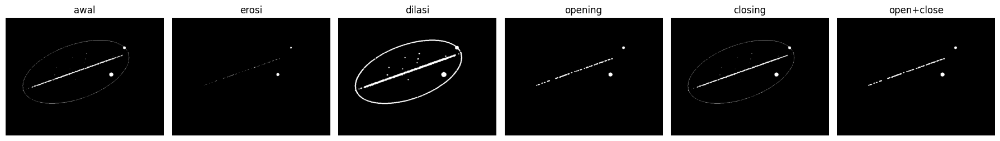

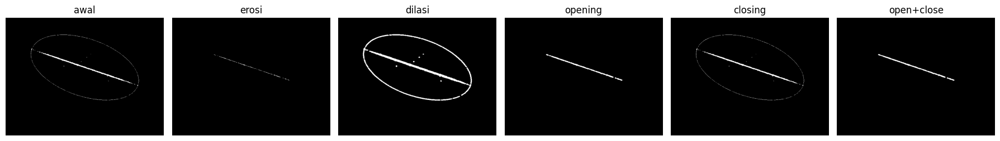

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       183    2646  0.101
1   teh_021.png       erosi        37     306  0.293
2   teh_021.png      dilasi        17    8969  0.037
3   teh_021.png     opening        21    1318  0.193
4   teh_021.png     closing       169    2764  0.098
5   teh_021.png  open+close        14    1379  0.185
6   teh_011.png        awal       197    2533      -
7   teh_011.png       erosi        34     313      -
8   teh_011.png      dilasi        11    8740      -
9   teh_011.png     opening         3    1505      -
10  teh_011.png     closing       179    2618      -
11  teh_011.png  open+close         2    1528      -


In [27]:
# Kode 3.2 Erosi, dilasi, opening, dan closing
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k,
k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN,
se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3));
plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel",
"IoU"]))

In [21]:
# Kode 3.3 Eksperimen k, bentuk, dan ukuran SE
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang":
cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) -
n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran",
"galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("./hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.51   0.19        14.25  15.65  21.15
          5       0.54   0.27         4.60   3.90   4.90
          7       0.65   0.48         3.05   1.80   1.70
  persegi 3       0.52   0.21         5.35   7.75   8.20
          5       0.58   0.36         3.65   3.35   3.35
          7       0.67   0.49         1.25   0.65   0.00
  silang  3       0.51   0.19        14.25  15.65  21.15
          5       0.54   0.26         5.80   6.60   8.45
          7       0.65   0.43         5.20   4.15   3.55
4 elips   3       0.56   0.32        10.40  12.05  13.55
          5       0.59   0.43         3.90   2.75   2.10
          7       0.66   0.53         1.50   0.60   0.45
  persegi 3       0.56   0.35         6.35   6.70   5.15
          5       0.63   0.48         2.85   1.60   0.85
          7       0.64   0.45  

In [30]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

In [33]:
# Kode 3.4 Gradien morfologi dibandingkan dengan Canny
baris = []

for _, d in label.iterrows():
    # --- Perhatikan 4 spasi di awal baris di bawah ini ---
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))
    # dilasi - erosi

    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)

    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])

# --- Bagian print berada di luar loop (tanpa spasi) ---
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.744     0.715
gelap                          0.982     0.693
kontras_rendah                 0.173     0.867
normal                         0.990     0.691
terang                         0.889     0.704


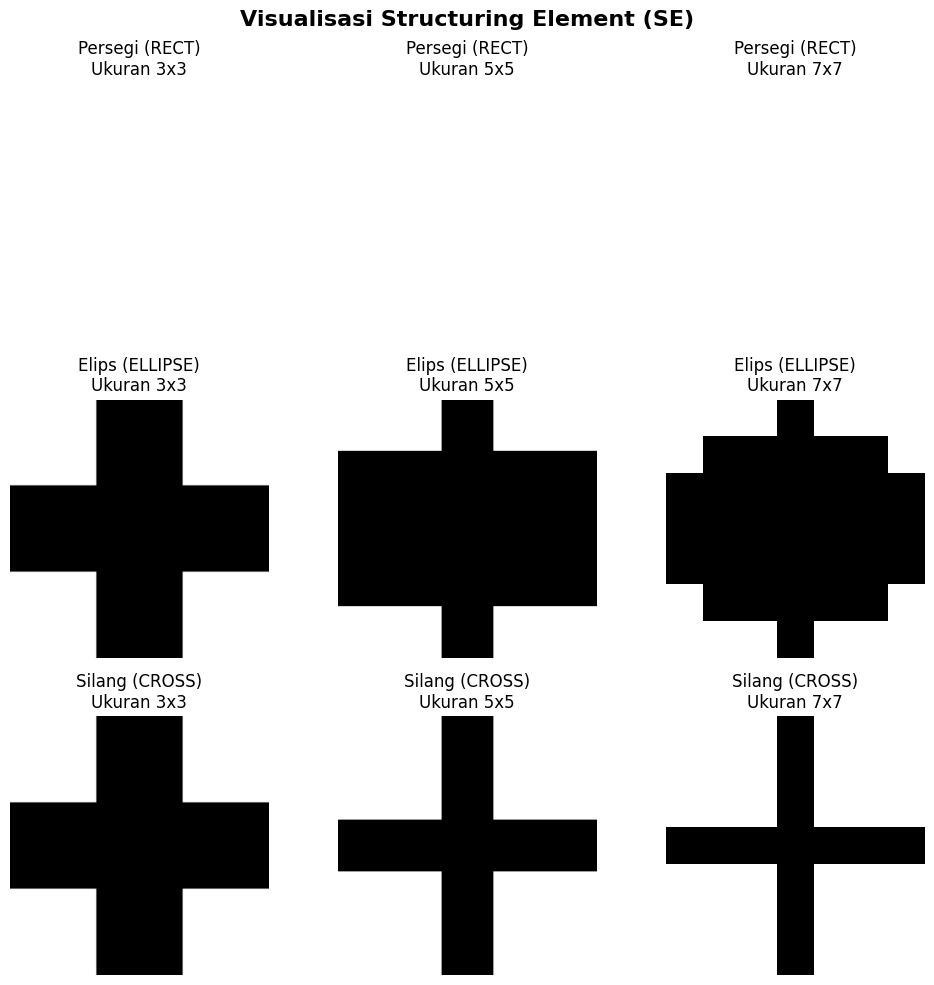

In [34]:
import cv2
import matplotlib.pyplot as plt

# 1. Siapkan daftar bentuk dan ukuran
bentuk_dict = {
    "Persegi (RECT)": cv2.MORPH_RECT,
    "Elips (ELLIPSE)": cv2.MORPH_ELLIPSE,
    "Silang (CROSS)": cv2.MORPH_CROSS
}
ukuran_list = [3, 5, 7]

# 2. Buat panel (3 baris untuk bentuk, 3 kolom untuk ukuran)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Visualisasi Structuring Element (SE)", fontsize=16, fontweight="bold")

for i, (nama_bentuk, kode_bentuk) in enumerate(bentuk_dict.items()):
    for j, uk in enumerate(ukuran_list):
        # Buat matriks SE
        se = cv2.getStructuringElement(kode_bentuk, (uk, uk))

        # Perbesar matriks agar terlihat jelas (scaling x40)
        # interpolation=cv2.INTER_NEAREST agar kotaknya tetap tajam
        se_besar = cv2.resize(se, (uk*40, uk*40), interpolation=cv2.INTER_NEAREST)

        # Tampilkan di subplot
        ax = axes[i, j]
        ax.imshow(se_besar, cmap="gray_r") # cmap="gray_r" agar nilai 1 jadi hitam, 0 jadi putih
        ax.set_title(f"{nama_bentuk}\nUkuran {uk}x{uk}")
        ax.axis("off")

plt.tight_layout()
plt.show()


1.   Bentuk Persegi (RECT): Memiliki area piksel yang paling padat. Operasi Opening dengan bentuk ini akan mengikis objek (bercak) secara kotak-kotak. Sangat baik untuk mempertahankan bentuk bercak yang cenderung bulat/beraturan, tapi cenderung menghilangkan detail tipis.
2.   Bentuk Elips (ELLIPSE): Bentuknya paling mendekati bentuk bercak asli (bulat). Saat ukurannya diperbesar (5x5 atau 7x7), bentuk ini paling bagus untuk menghaluskan tepi bercak tanpa membuat sudut yang kaku.
1.   Bentuk Silang (CROSS): Area pikselnya paling sedikit (hanya berbentuk plus/tanda tambah). Ini membuat proses erosi/dilasi lebih "lunak". Bentuk ini sangat efektif jika bercak yang ingin dihilangkan ukurannya sangat kecil, karena tidak terlalu merusak struktur objek utama.
2.   Pengaruh Ukuran (3, 5, 7): Semakin besar ukuran SE (misal dari 3x3 menjadi 7x7), semakin banyak noise/tulang daun kecil yang bisa dihapus. Tapi jika ukurannya terlalu besar (7x7), bercak asli yang kecil juga bisa ikut terhapus. Inilah alasan mengapa di Kode 3.3 kita mengeksperimenkan nilai uk untuk mencari ukuran yang paling pas (galat paling kecil, IoU paling tinggi).




konektivitas 4: 8 komponen
konektivitas 8: 8 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      202     38.66         50.6       0.99         1.14  377  185
1      2      398     76.18         73.9       0.91         1.04  318  194
2      3      781    149.49        428.9       0.05        33.06  273  275
3      4      116     22.20         37.8       1.02         1.00  374  277
4      5      715    136.86         96.4       0.97         1.04  309  313
5      6       51      9.76         30.1       0.71         3.00  174  317
6      7      264     50.53         58.6       0.97         1.12  241  343
7      8      317     60.68         63.5       0.99         1.06  188  363


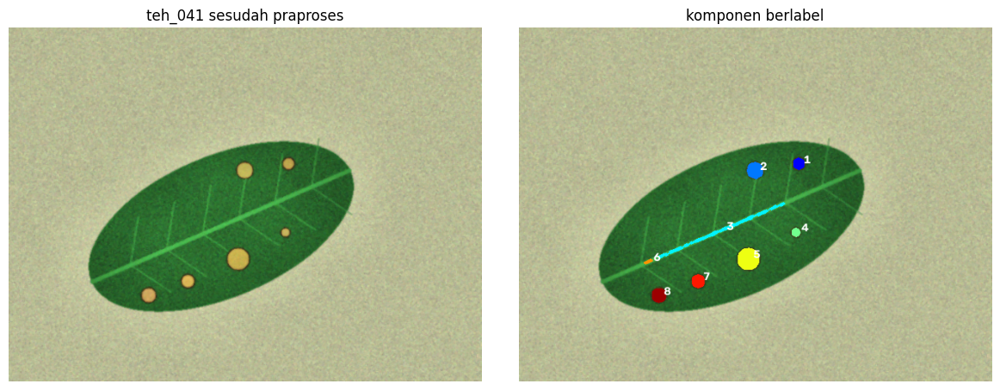

In [37]:
# Bagian 4. Komponen Terhubung dan Pengukuran Bercak
# Kode 4.1 Komponen terhubung dan pengukuran setiap bercak
MM_PER_PX = 0.4375
# dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px (dirapikan jadi 1 baris komentar)

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []

    for i in range(1, n):
        # Baris 'kontur, _ = cv2.findContours(...)' yang terpotong disatukan
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)

        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])

    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

# --- Bagian di luar fungsi ---
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]

for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

In [38]:
# Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >=
bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20,
0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun),
cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas",
values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah >
0).groupby("aturan").palsu.sum())


kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           2.45    1.25   0.80
luas + kebulatan + rasio   1.75    0.65   0.25
luas >= 20                 2.95    2.05   1.45
tanpa saring               3.90    2.75   2.10
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             4
luas + kebulatan + rasio     4
luas >= 20                   8
tanpa saring                11
Name: palsu, dtype: int64


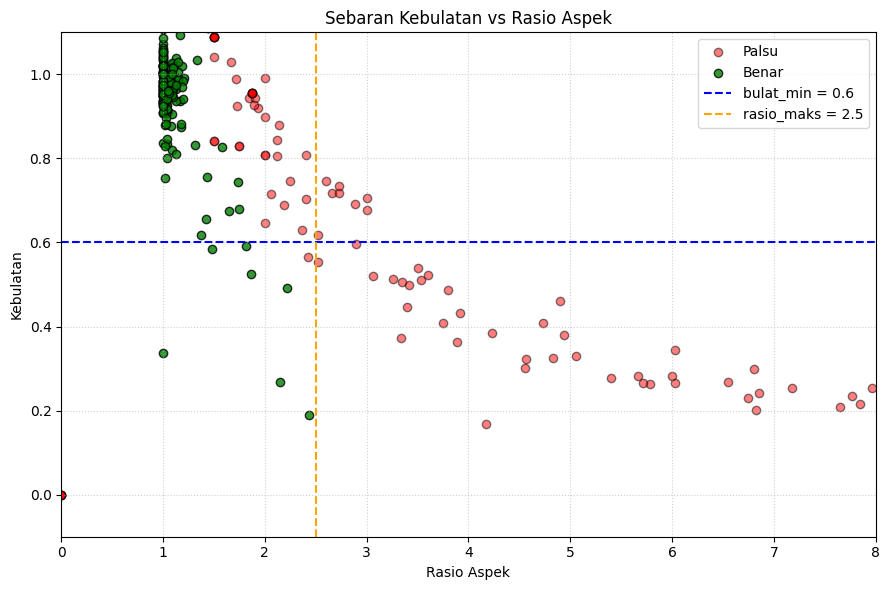

Total komponen: 327
Jumlah bercak asli (benar): 169
Jumlah noise (palsu): 158


In [39]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Langkah 4.4 Kerjakan sendiri: dasar ambang penyaringan.
# list buat nampung data
data = []

# ambil semua citra dari label
for index, row in label.iterrows():
    gambar, mask_d, mask_b = muat(row.nama_file)

    # praproses dan cari bercak
    img_pra = praproses(gambar, PARAM)
    daun = mask_daun_awal(img_pra)
    bercak = bercak_awal(img_pra, daun)

    # bersihkan pake morfologi
    se = SE(5)
    bersih = cv2.morphologyEx(bercak, cv2.MORPH_OPEN, se)
    bersih = cv2.morphologyEx(bersih, cv2.MORPH_CLOSE, se)

    # cari komponen
    n, lbl, st, c = cv2.connectedComponentsWithStats((bersih > 0).astype(np.uint8), connectivity=8)

    # cek satu per satu komponen
    for i in range(1, n):
        objek = (lbl == i)

        # hitung irisan sama mask acuan
        iris = np.sum(objek & (mask_b > 0))
        total = np.sum(objek)

        # tentuin benar atau palsu
        if total > 0:
            persen = iris / total
            status = "benar" if persen > 0.5 else "palsu"
        else:
            status = "palsu"

        # hitung luas, keliling, kebulatan, rasio
        luas = int(st[i, cv2.CC_STAT_AREA])

        kontur, _ = cv2.findContours(objek.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

        if len(kontur) > 0:
            kll = cv2.arcLength(kontur[0], True)

            # rumus kebulatan
            if kll == 0:
                bulat = 0.0
            else:
                bulat = 4 * np.pi * luas / (kll ** 2)

            # rumus rasio aspek
            w, h = cv2.minAreaRect(kontur[0])[1]
            if min(w, h) == 0:
                rasio = 0
            else:
                rasio = max(w, h) / min(w, h)

            # masukin ke list
            data.append([row.nama_file, row.kelas, luas, bulat, rasio, status])

# ubah ke dataframe
df = pd.DataFrame(data, columns=["file", "kelas", "luas", "kebulatan", "rasio", "status"])

# grafik sebar
plt.figure(figsize=(9, 6))

# pisahin datanya
data_benar = df[df["status"] == "benar"]
data_palsu = df[df["status"] == "palsu"]

# plot yang palsu pake warna merah
plt.scatter(data_palsu["rasio"], data_palsu["kebulatan"], c="red", alpha=0.5, label="Palsu", edgecolors="black")

# plot yang benar pake warna hijau
plt.scatter(data_benar["rasio"], data_benar["kebulatan"], c="green", alpha=0.8, label="Benar", edgecolors="black")

# garis bantu buat nentuin ambang batas
plt.axhline(y=0.6, color="blue", linestyle="--", label="bulat_min = 0.6")
plt.axvline(x=2.5, color="orange", linestyle="--", label="rasio_maks = 2.5")

# seting grafik
plt.title("Sebaran Kebulatan vs Rasio Aspek")
plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.xlim(0, 8)
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()

# simpan
plt.savefig("./hasil/p6_scatter_komponen.png", dpi=300)
plt.show()

print("Total komponen:", len(df))
print("Jumlah bercak asli (benar):", len(data_benar))
print("Jumlah noise (palsu):", len(data_palsu))

Galat absolut rerata persen bercak: 0.606
Korelasi persen prediksi vs acuan : 0.852
Akurasi kelas                     : 0.333

=== Crosstab Kelas Acuan vs Prediksi ===
prediksi       Berat  Ringan  Sehat
acuan                              
Bercak Berat      17       1      2
Bercak Ringan      0      18      2
Sehat              0       0     20

=== Akurasi Berdasarkan Kondisi Cahaya ===
kondisi
bayangan          0.33
gelap             0.33
kontras_rendah    0.33
normal            0.33
terang            0.33
Name: benar, dtype: float64


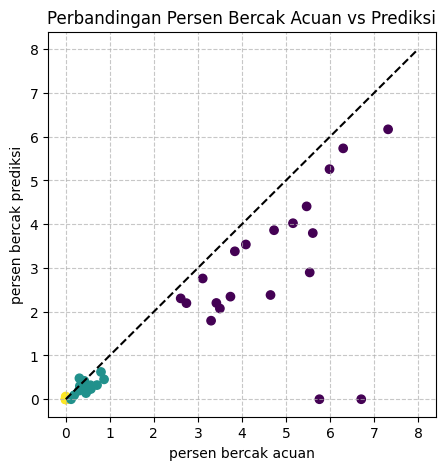

In [42]:
# Bagian 5. Integrasi: Modul Analisis Bercak SIMUTEH
# Kode 5.2 Evaluasi modul bercak.py
import importlib
import bercak
importlib.reload(bercak)

# Isi PB (Parameter Bercak) sesuai temuan Anda di Langkah 4.4
# Misalnya jika Anda ingin menimpa parameter default, isi di sini.
# Jika dibiarkan kosong {}, maka akan memakai PARAM_BERCAK default.
PB = {}

bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)

    baris.append([
        d.nama_file,
        d.kelas,
        d.kondisi_cahaya,
        d.persen_bercak,
        h["persen_bercak"],
        jumlah_komponen(mb),
        h["jumlah_bercak"],
        h["kelas"]
    ])

ev = pd.DataFrame(baris, columns=[
    "nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
    "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"
])

# Mapping kelas acuan
ev["kelas_acuan"] = ev.kelas.map({
    "sehat": "Sehat",
    "ringan": "Bercak Ringan",
    "berat": "Bercak Berat"
})

# Simpan ke CSV (path disesuaikan untuk Colab)
ev.to_csv("./hasil/p6_evaluasi_bercak.csv", index=False)

# --- Tampilkan Metrik ---
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))

print("\n=== Crosstab Kelas Acuan vs Prediksi ===")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))

print("\n=== Akurasi Berdasarkan Kondisi Cahaya ===")
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

# --- Scatter Plot ---
plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Perbandingan Persen Bercak Acuan vs Prediksi")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

Ditemukan 40 citra yang salah prediksi kelas.



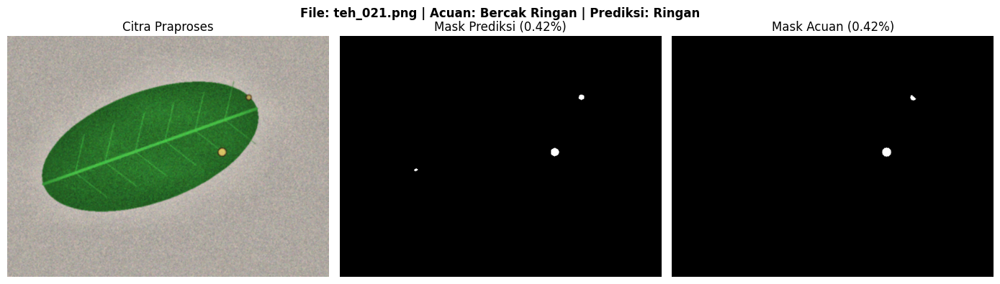

Analisis untuk teh_021.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.42% vs Acuan: 0.42%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



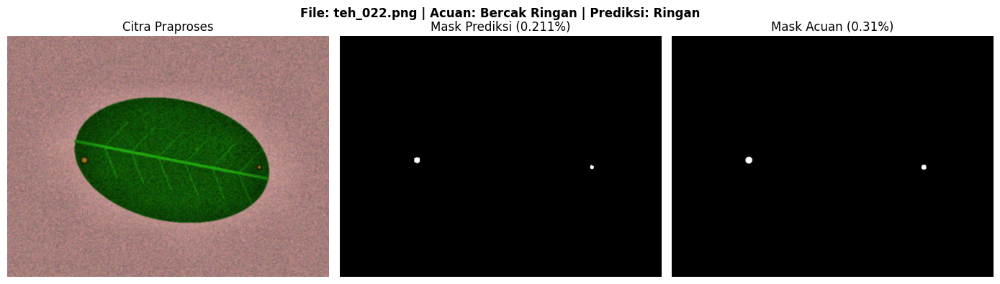

Analisis untuk teh_022.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.211% vs Acuan: 0.31%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



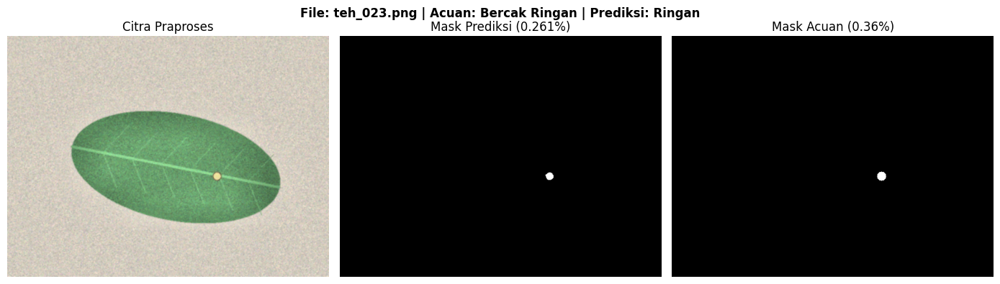

Analisis untuk teh_023.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.261% vs Acuan: 0.36%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



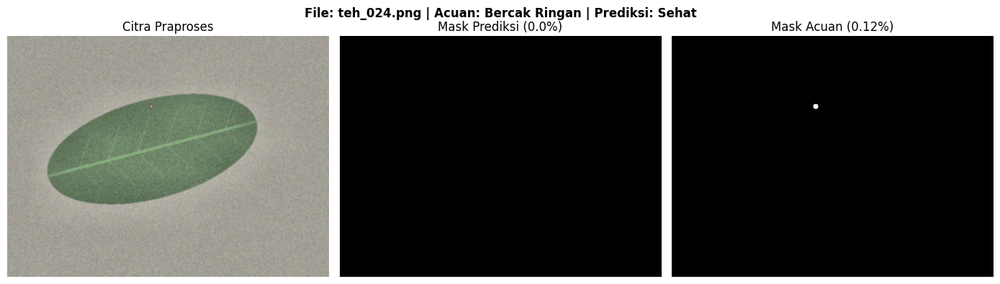

Analisis untuk teh_024.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.0% vs Acuan: 0.12%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



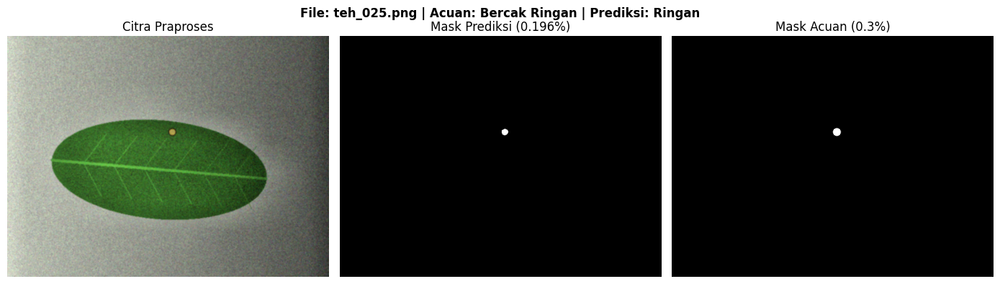

Analisis untuk teh_025.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.196% vs Acuan: 0.3%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



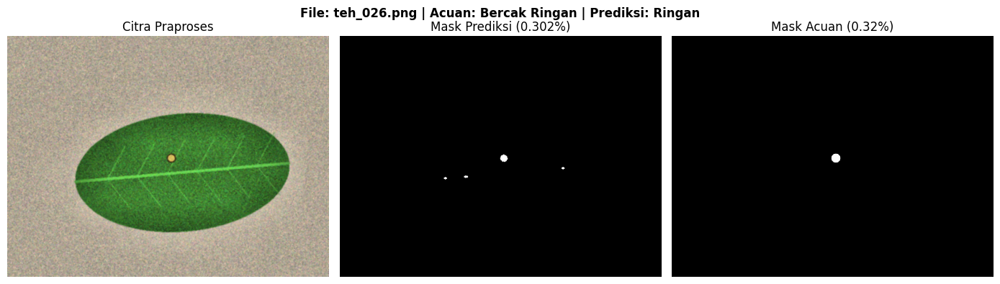

Analisis untuk teh_026.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.302% vs Acuan: 0.32%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



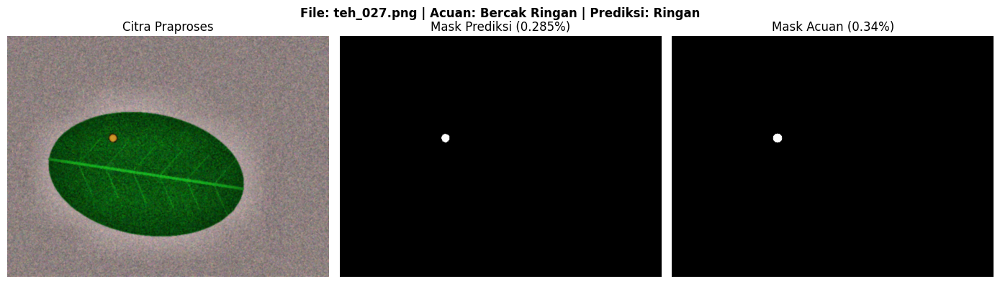

Analisis untuk teh_027.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.285% vs Acuan: 0.34%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



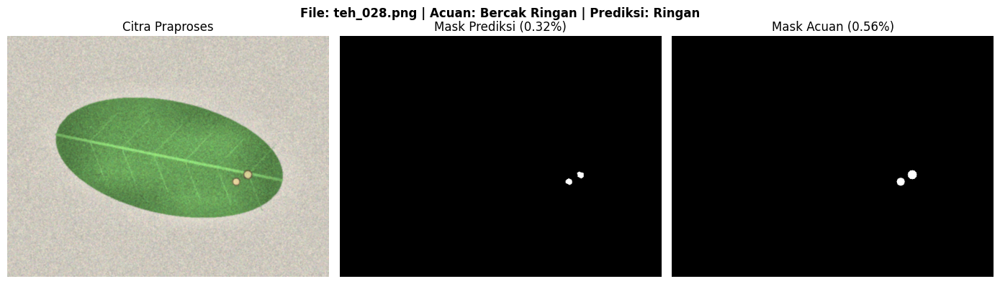

Analisis untuk teh_028.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.32% vs Acuan: 0.56%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



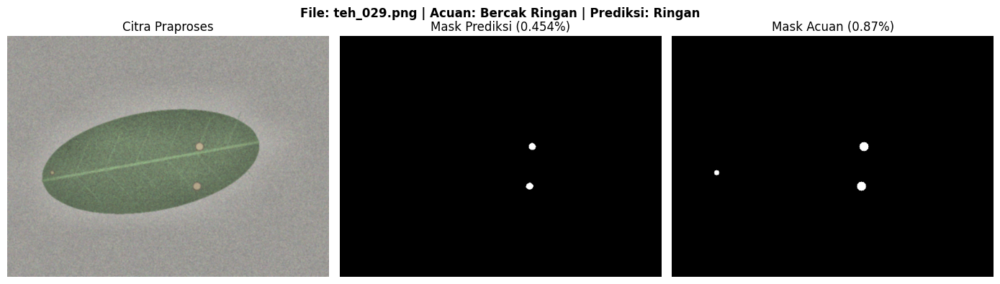

Analisis untuk teh_029.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.454% vs Acuan: 0.87%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



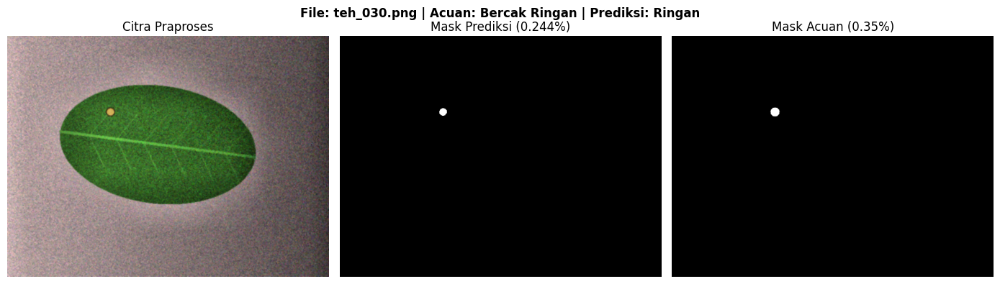

Analisis untuk teh_030.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.244% vs Acuan: 0.35%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



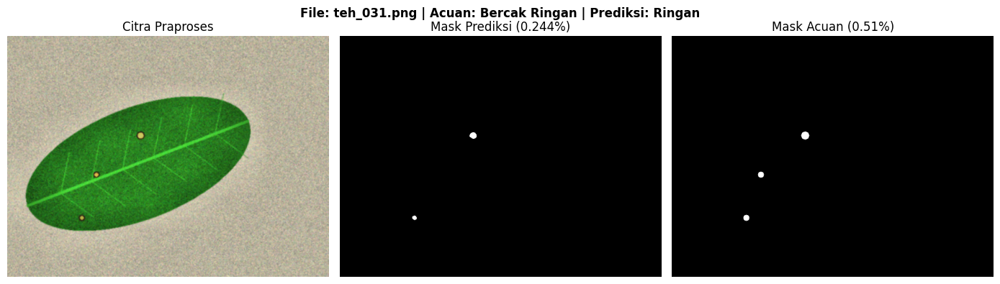

Analisis untuk teh_031.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.244% vs Acuan: 0.51%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



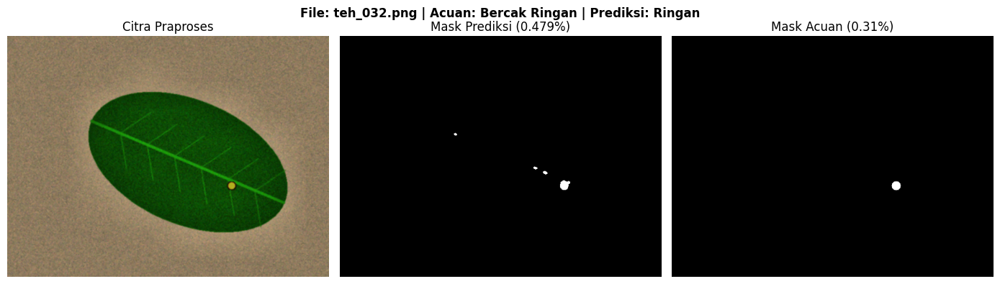

Analisis untuk teh_032.png:
-> Terjadi OVER-estimasi (Prediksi: 0.479% vs Acuan: 0.31%).
-> Penyebab: Banyak noise, bayangan, atau tulang daun yang ikut terdeteksi sebagai bercak.
------------------------------------------------------------



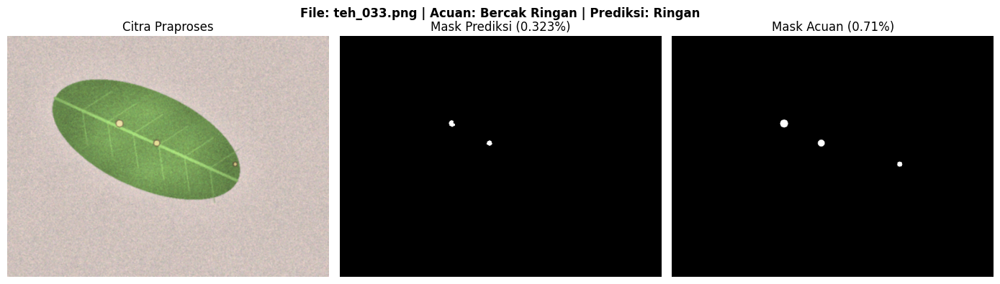

Analisis untuk teh_033.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.323% vs Acuan: 0.71%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



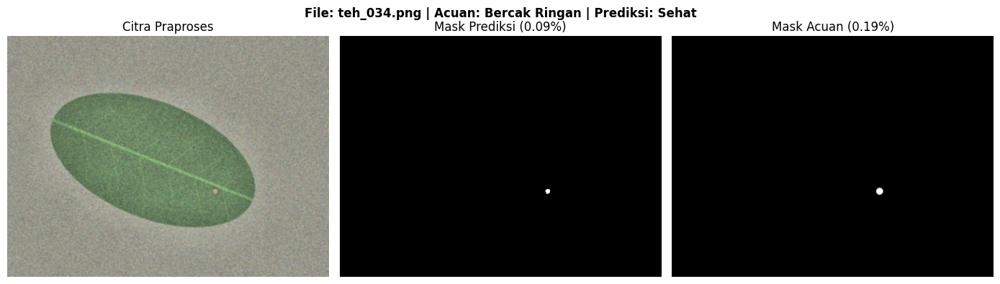

Analisis untuk teh_034.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.09% vs Acuan: 0.19%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



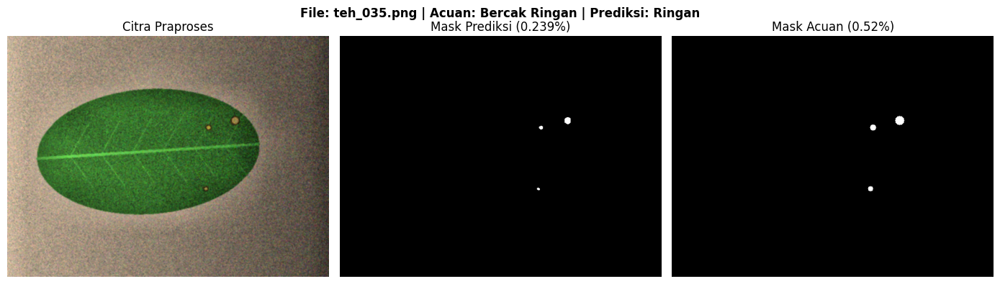

Analisis untuk teh_035.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.239% vs Acuan: 0.52%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



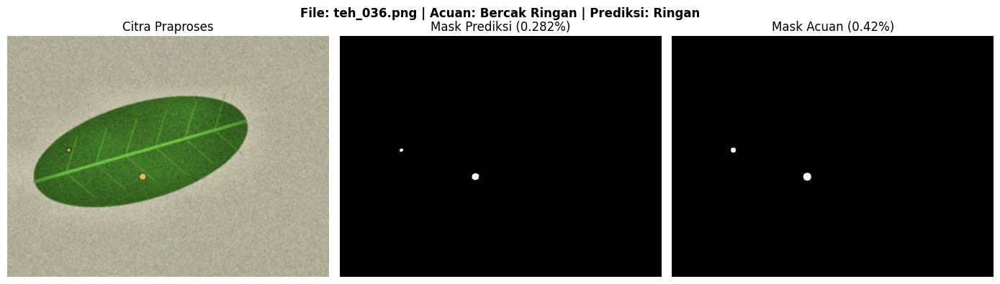

Analisis untuk teh_036.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.282% vs Acuan: 0.42%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



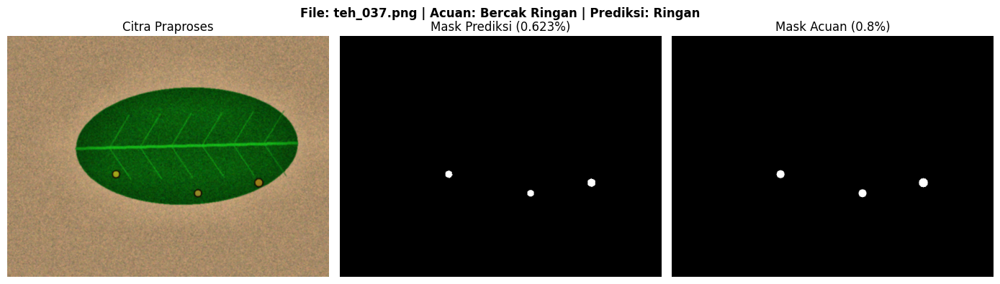

Analisis untuk teh_037.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.623% vs Acuan: 0.8%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



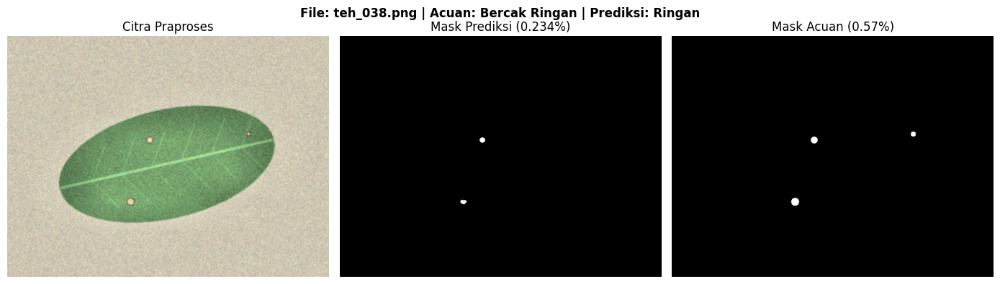

Analisis untuk teh_038.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.234% vs Acuan: 0.57%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



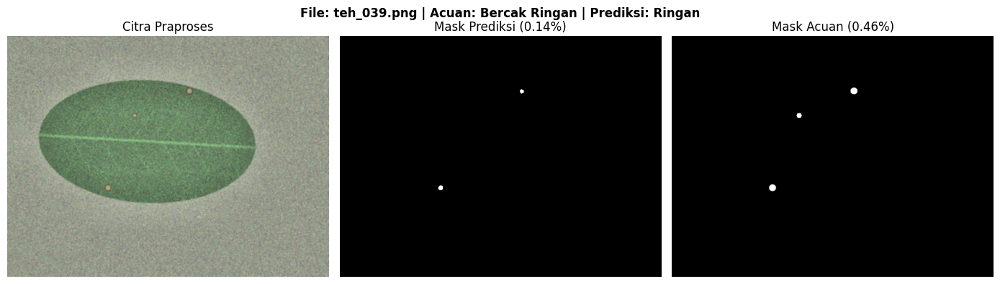

Analisis untuk teh_039.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.14% vs Acuan: 0.46%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



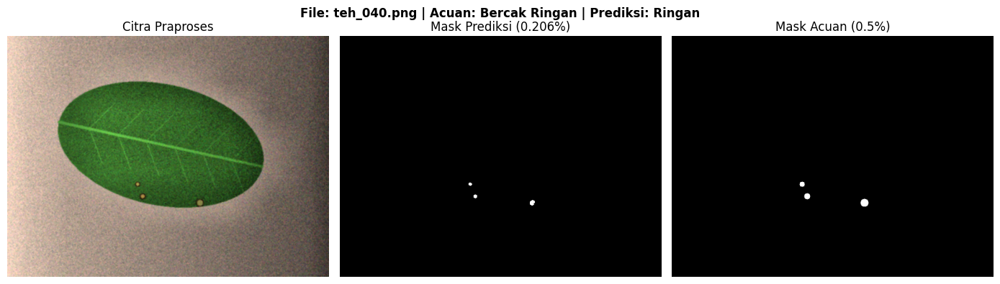

Analisis untuk teh_040.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.206% vs Acuan: 0.5%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



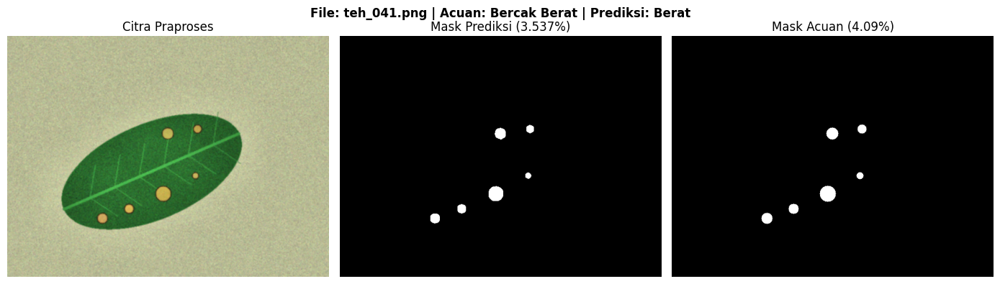

Analisis untuk teh_041.png:
-> Terjadi UNDER-estimasi (Prediksi: 3.537% vs Acuan: 4.09%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



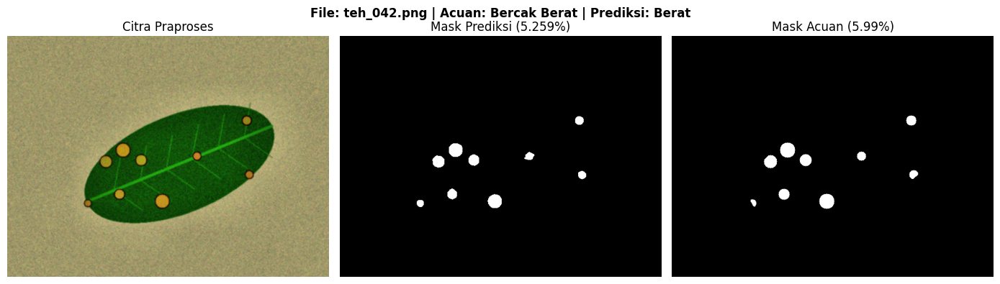

Analisis untuk teh_042.png:
-> Terjadi UNDER-estimasi (Prediksi: 5.259% vs Acuan: 5.99%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



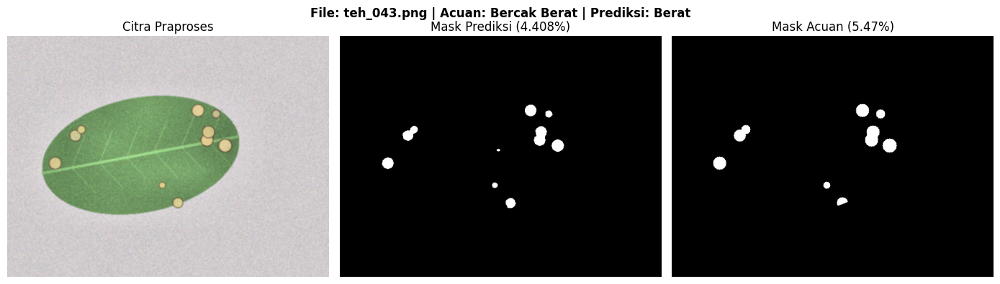

Analisis untuk teh_043.png:
-> Terjadi UNDER-estimasi (Prediksi: 4.408% vs Acuan: 5.47%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



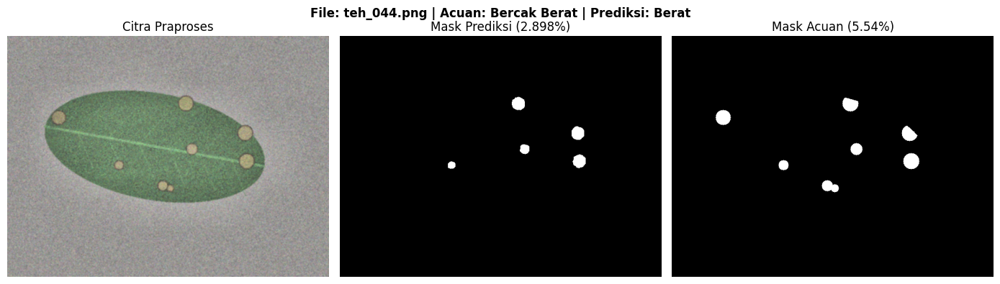

Analisis untuk teh_044.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.898% vs Acuan: 5.54%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



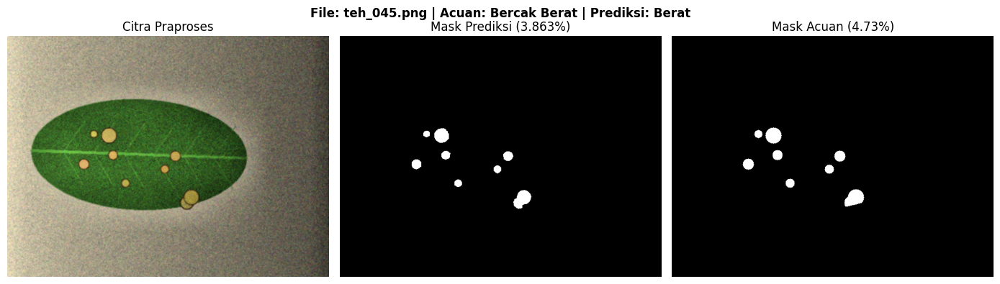

Analisis untuk teh_045.png:
-> Terjadi UNDER-estimasi (Prediksi: 3.863% vs Acuan: 4.73%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



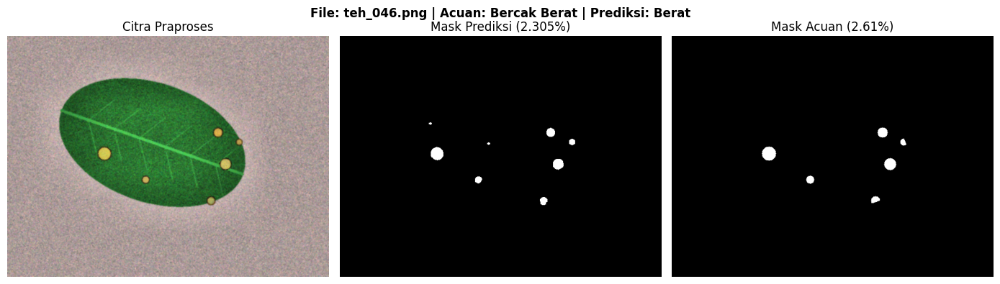

Analisis untuk teh_046.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.305% vs Acuan: 2.61%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



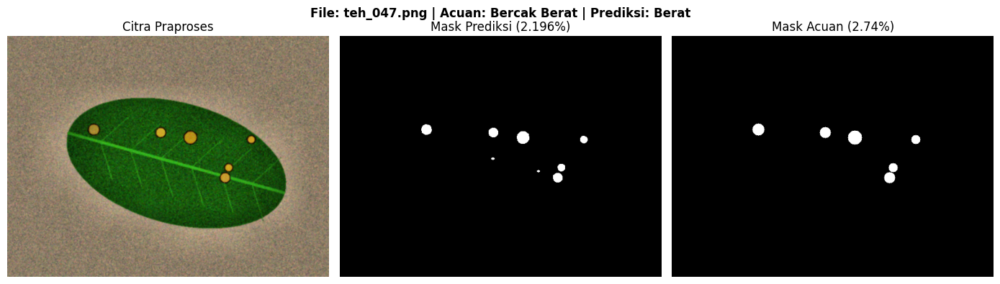

Analisis untuk teh_047.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.196% vs Acuan: 2.74%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



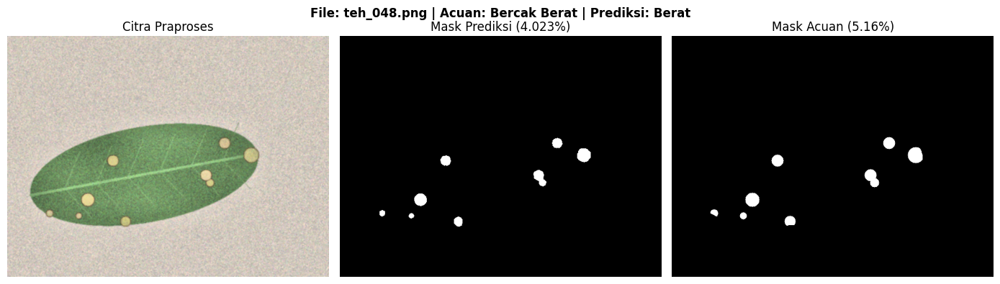

Analisis untuk teh_048.png:
-> Terjadi UNDER-estimasi (Prediksi: 4.023% vs Acuan: 5.16%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



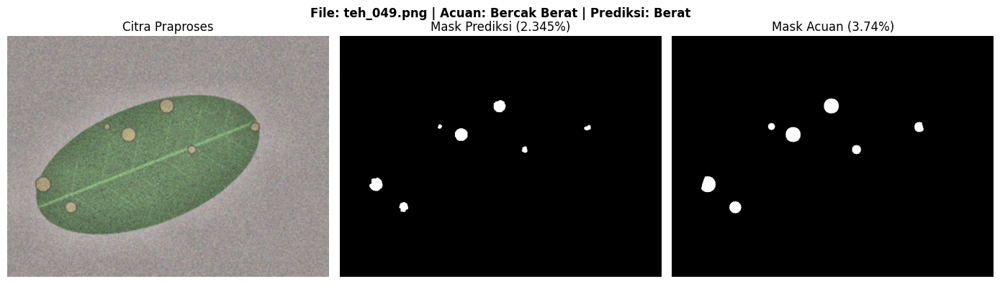

Analisis untuk teh_049.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.345% vs Acuan: 3.74%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



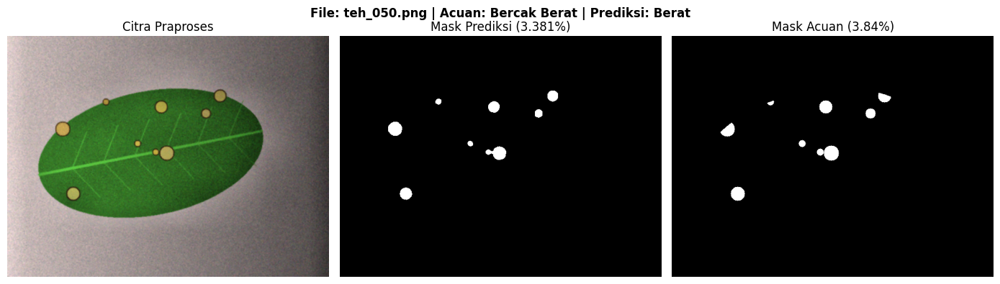

Analisis untuk teh_050.png:
-> Terjadi UNDER-estimasi (Prediksi: 3.381% vs Acuan: 3.84%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



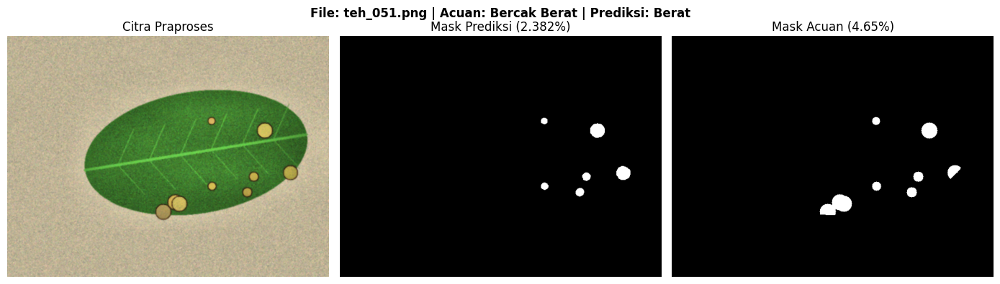

Analisis untuk teh_051.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.382% vs Acuan: 4.65%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



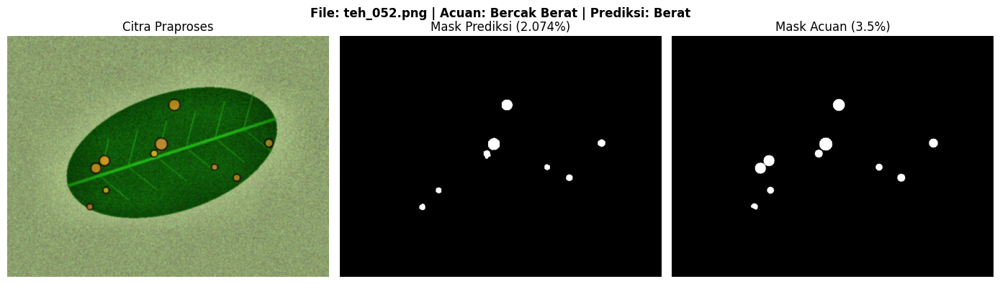

Analisis untuk teh_052.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.074% vs Acuan: 3.5%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



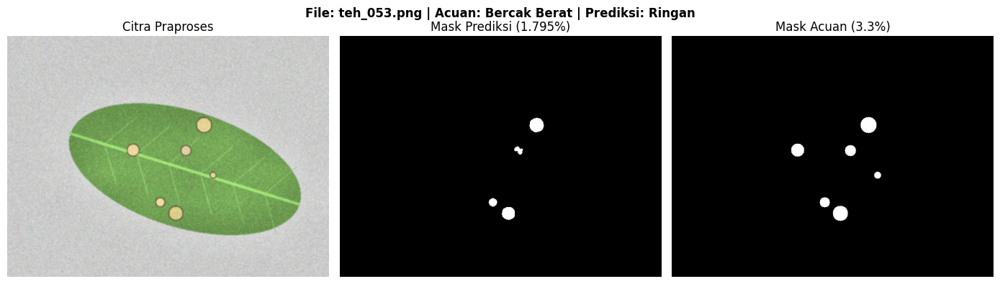

Analisis untuk teh_053.png:
-> Terjadi UNDER-estimasi (Prediksi: 1.795% vs Acuan: 3.3%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



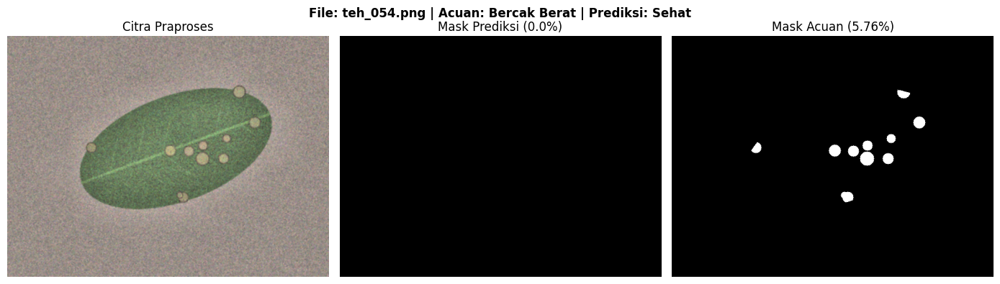

Analisis untuk teh_054.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.0% vs Acuan: 5.76%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



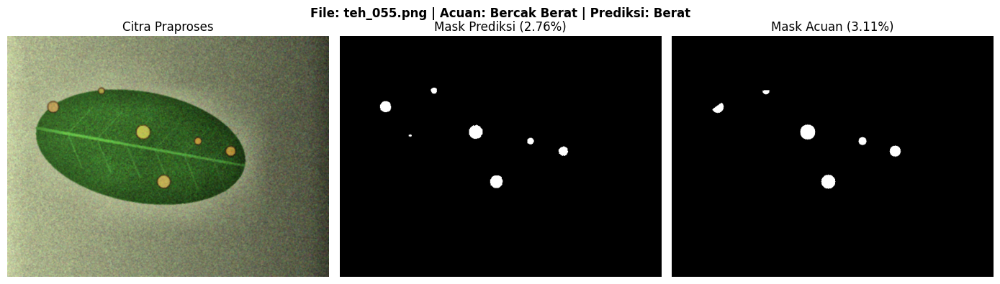

Analisis untuk teh_055.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.76% vs Acuan: 3.11%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



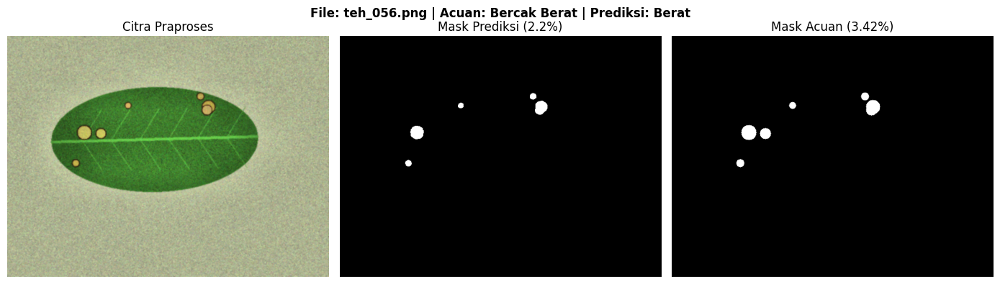

Analisis untuk teh_056.png:
-> Terjadi UNDER-estimasi (Prediksi: 2.2% vs Acuan: 3.42%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



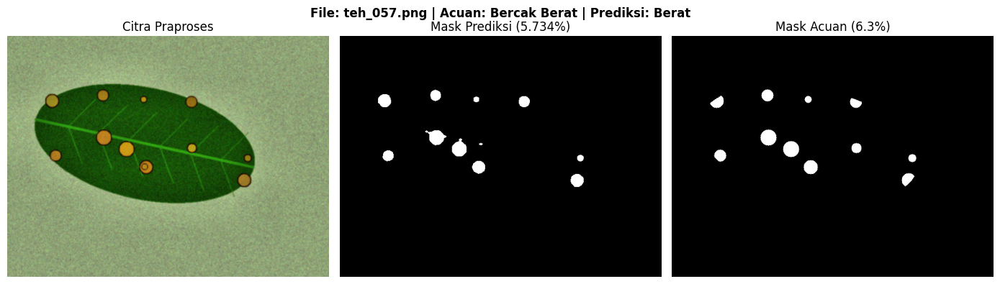

Analisis untuk teh_057.png:
-> Terjadi UNDER-estimasi (Prediksi: 5.734% vs Acuan: 6.3%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



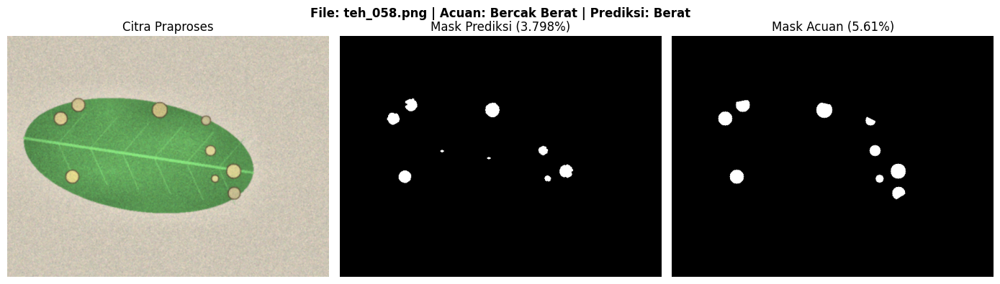

Analisis untuk teh_058.png:
-> Terjadi UNDER-estimasi (Prediksi: 3.798% vs Acuan: 5.61%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



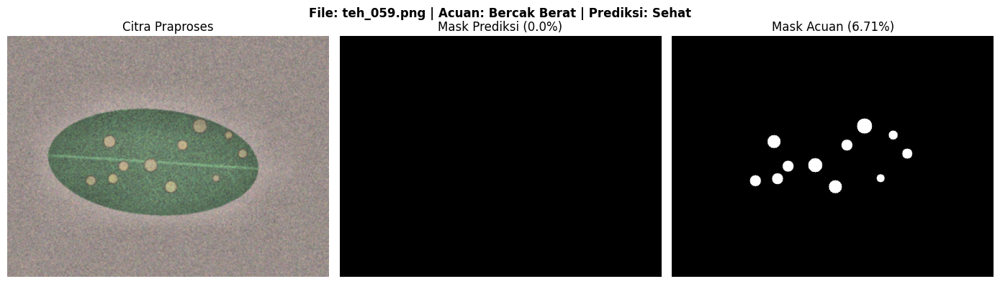

Analisis untuk teh_059.png:
-> Terjadi UNDER-estimasi (Prediksi: 0.0% vs Acuan: 6.71%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



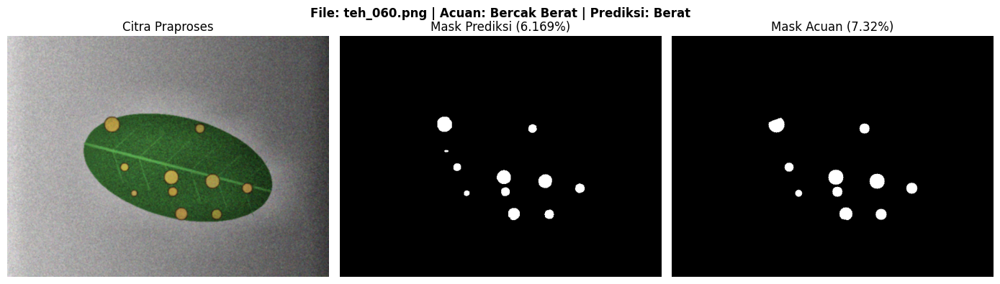

Analisis untuk teh_060.png:
-> Terjadi UNDER-estimasi (Prediksi: 6.169% vs Acuan: 7.32%).
-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.
------------------------------------------------------------



In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Ambil data yang prediksinya salah
salah = ev[ev["kelas_prediksi"] != ev["kelas_acuan"]]

print(f"Ditemukan {len(salah)} citra yang salah prediksi kelas.\n")

# 2. Loop untuk nampilin gambar dan analisis
for i, (_, row) in enumerate(salah.iterrows()):
    nama_file = row["nama"]

    # load gambar asli dan mask acuan
    img, md, mb = muat(nama_file)

    # proses ulang buat dapetin mask hasil prediksi
    img_pra = praproses(img, PARAM)
    hasil = bercak.analisis_daun(img_pra, PB)
    mask_pred = hasil["mask_bercak"]

    # bikin figure 1 baris 3 kolom
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))

    # Panel 1: citra hasil praproses
    # convert BGR ke RGB biar warnanya gak aneh di matplotlib
    ax[0].imshow(cv2.cvtColor(img_pra, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Citra Praproses")
    ax[0].axis("off")

    # Panel 2: mask prediksi
    ax[1].imshow(mask_pred, cmap="gray")
    ax[1].set_title(f"Mask Prediksi ({row['persen_prediksi']}%)")
    ax[1].axis("off")

    # Panel 3: mask acuan
    ax[2].imshow(mb, cmap="gray")
    ax[2].set_title(f"Mask Acuan ({row['persen_acuan']}%)")
    ax[2].axis("off")

    # set judul utama
    fig.suptitle(f"File: {nama_file} | Acuan: {row['kelas_acuan']} | Prediksi: {row['kelas_prediksi']}",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

    # 3. Print penyebab kesalahannya
    print(f"Analisis untuk {nama_file}:")

    if row['persen_prediksi'] > row['persen_acuan']:
        print(f"-> Terjadi OVER-estimasi (Prediksi: {row['persen_prediksi']}% vs Acuan: {row['persen_acuan']}%).")
        print("-> Penyebab: Banyak noise, bayangan, atau tulang daun yang ikut terdeteksi sebagai bercak.")
    else:
        print(f"-> Terjadi UNDER-estimasi (Prediksi: {row['persen_prediksi']}% vs Acuan: {row['persen_acuan']}%).")
        print("-> Penyebab: Bercak ukurannya terlalu kecil atau warnanya pudar, sehingga hilang saat proses morfologi (opening/closing) atau tersaring oleh batas luas minimal.")

    print("-" * 60 + "\n")

In [45]:
import os

os.chdir("/content/simuteh-2330511035")

with open("README.md", "r", encoding="utf-8") as f:
    print(f.read())

# SIMUTEH
## Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra
### Computer Vision – Digital Image Processing

SIMUTEH merupakan proyek praktikum **Computer Vision** yang berfokus pada pengolahan dan analisis citra daun teh. Proyek ini menerapkan teknik pengolahan citra untuk menganalisis warna, histogram, mengurangi derau, serta meningkatkan kualitas citra sebelum digunakan pada tahap analisis berikutnya.

Proyek ini menggunakan dataset sintetis dan dikembangkan menggunakan Python, OpenCV, serta Google Colab. Hasil pengujian bersifat ilustratif dan belum menjadi acuan diagnosis penyakit tanaman secara langsung.

---

## 1. Tujuan Proyek

1. Menganalisis karakteristik warna citra daun teh.
2. Mempelajari histogram dan teknik peningkatan kontras.
3. Menerapkan konvolusi dan penapisan citra.
4. Mengurangi derau dengan mempertahankan detail bercak.
5. Menyusun dan mengevaluasi rangkaian praproses citra daun teh.

## 2. Teknologi dan Lingkungan

| Komponen | Versi |
|---|---|
| Python | 3.13